In [2]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'

In [3]:
import torch
print(torch.backends.mps.is_available())

True


In [4]:
import pickle
import pandas as pd

with open("data/LSWMD_converted.pkl", "rb") as f:
    data_dict = pickle.load(f)

df = pd.DataFrame(data_dict)
print(f"Loaded {len(df)} wafers")
df.head()

Loaded 811457 wafers


,waferMap,lotName,waferIndex,dieSize,failureType
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",lot1,1.0,1683.0,[[none]]
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",lot1,2.0,1683.0,[[none]]
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",lot1,3.0,1683.0,[[none]]
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",lot1,4.0,1683.0,[[none]]
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",lot1,5.0,1683.0,[[none]]


Shape: (45, 48)
Unique values: [0 1 2]


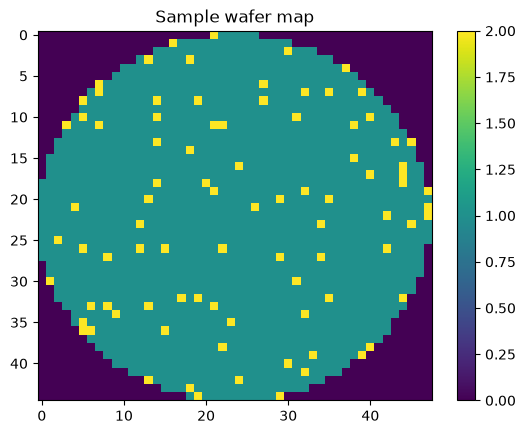

In [5]:
import numpy as np
import matplotlib.pyplot as plt

sample_wafer = np.array(df.iloc[0]['waferMap'])
print("Shape:", sample_wafer.shape)
print("Unique values:", np.unique(sample_wafer))

plt.imshow(sample_wafer, cmap='viridis')
plt.title("Sample wafer map")
plt.colorbar()
plt.show()


In [6]:
print(df.iloc[0]['failureType'])
print(df['failureType'].apply(lambda x: len(x) if hasattr(x, '__len__') else 0).value_counts().head())

[['none']]
failureType
0    638507
1    172950
Name: count, dtype: int64


In [7]:
def extract_label(x):
    try:
        if hasattr(x, '__len__') and len(x) > 0:
            flat = np.array(x).flatten()
            return flat[0] if flat[0] != '' else None
        return None
    except Exception:
        return None

df['label'] = df['failureType'].apply(extract_label)
labeled_df = df[df['label'].notna()].reset_index(drop=True)

print(f"Labeled wafers: {len(labeled_df)}")
print(labeled_df['label'].value_counts())

Labeled wafers: 172950
label
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64


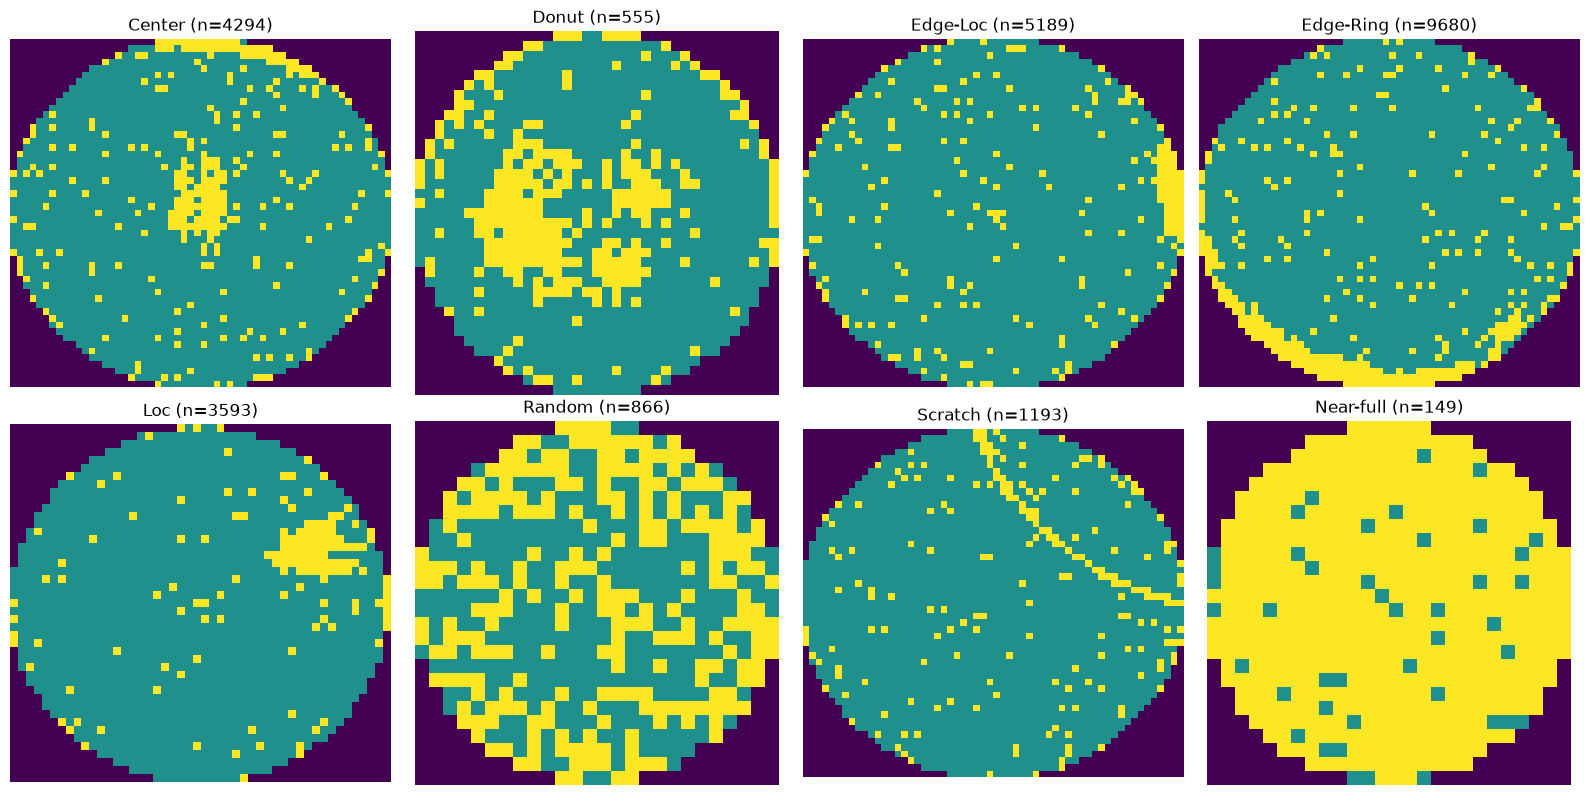

In [8]:
FAILURE_TYPES = ["Center", "Donut", "Edge-Loc", "Edge-Ring",
                  "Loc", "Random", "Scratch", "Near-full", "none"]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()

for i, label in enumerate(FAILURE_TYPES[:8]):  # 8 real defect types, skip "none"
    subset = labeled_df[labeled_df['label'] == label]
    wafer_map = np.array(subset.iloc[0]['waferMap'])
    axes[i].imshow(wafer_map, cmap='viridis')
    axes[i].set_title(f"{label} (n={len(subset)})")
    axes[i].axis('off')

plt.tight_layout()
plt.show()

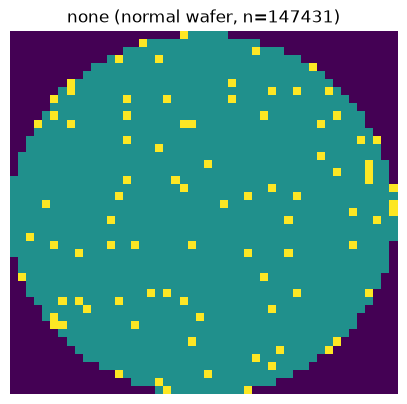

In [9]:
none_wafer = np.array(labeled_df[labeled_df['label'] == 'none'].iloc[0]['waferMap'])
plt.figure(figsize=(5, 5))
plt.imshow(none_wafer, cmap='viridis')
plt.title(f"none (normal wafer, n={len(labeled_df[labeled_df['label']=='none'])})")
plt.axis('off')
plt.show()

In [10]:
print(df.shape)
print(df.columns.tolist())
print(df.dtypes)
df.head()

(811457, 6)
['waferMap', 'lotName', 'waferIndex', 'dieSize', 'failureType', 'label']
waferMap        object
lotName            str
waferIndex     float64
dieSize        float64
failureType     object
label              str
dtype: object


,waferMap,lotName,waferIndex,dieSize,failureType,label
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",lot1,1.0,1683.0,[[none]],none
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",lot1,2.0,1683.0,[[none]],none
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",lot1,3.0,1683.0,[[none]],none
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",lot1,4.0,1683.0,[[none]],none
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",lot1,5.0,1683.0,[[none]],none


In [11]:
# 1. Class distribution
print(df['label'].value_counts())

# 2. Check if wafer map shapes vary
df['map_shape'] = df['waferMap'].apply(lambda x: (len(x), len(x[0])))
print(df['map_shape'].value_counts().head(10))

# 3. Any missing labels?
print(df['label'].isna().sum())

label
none         147431
Edge-Ring      9680
Edge-Loc       5189
Center         4294
Loc            3593
Scratch        1193
Random          866
Donut           555
Near-full       149
Name: count, dtype: int64
map_shape
(32, 29)    108687
(25, 27)     64083
(49, 39)     39323
(26, 26)     30078
(30, 34)     29513
(33, 33)     23886
(33, 29)     20276
(39, 37)     15327
(52, 59)     14812
(31, 31)     14569
Name: count, dtype: int64
638507


In [12]:
# Drop unlabeled rows — we can't train or evaluate on wafers with no ground truth
df_labeled = df.dropna(subset=['label']).reset_index(drop=True)
print(f"Labeled wafers: {len(df_labeled)}")

from sklearn.model_selection import train_test_split

# Stratified split: keeps the same class proportions in train and test,
# critical here because some classes (e.g. Near-full) only have 149 examples total
train_df, test_df = train_test_split(
    df_labeled,
    test_size=0.2,
    stratify=df_labeled['label'],
    random_state=42
)

print(f"Train: {len(train_df)}, Test: {len(test_df)}")
print(train_df['label'].value_counts())

Labeled wafers: 172950
Train: 138360, Test: 34590
label
none         117945
Edge-Ring      7744
Edge-Loc       4151
Center         3435
Loc            2875
Scratch         954
Random          693
Donut           444
Near-full       119
Name: count, dtype: int64


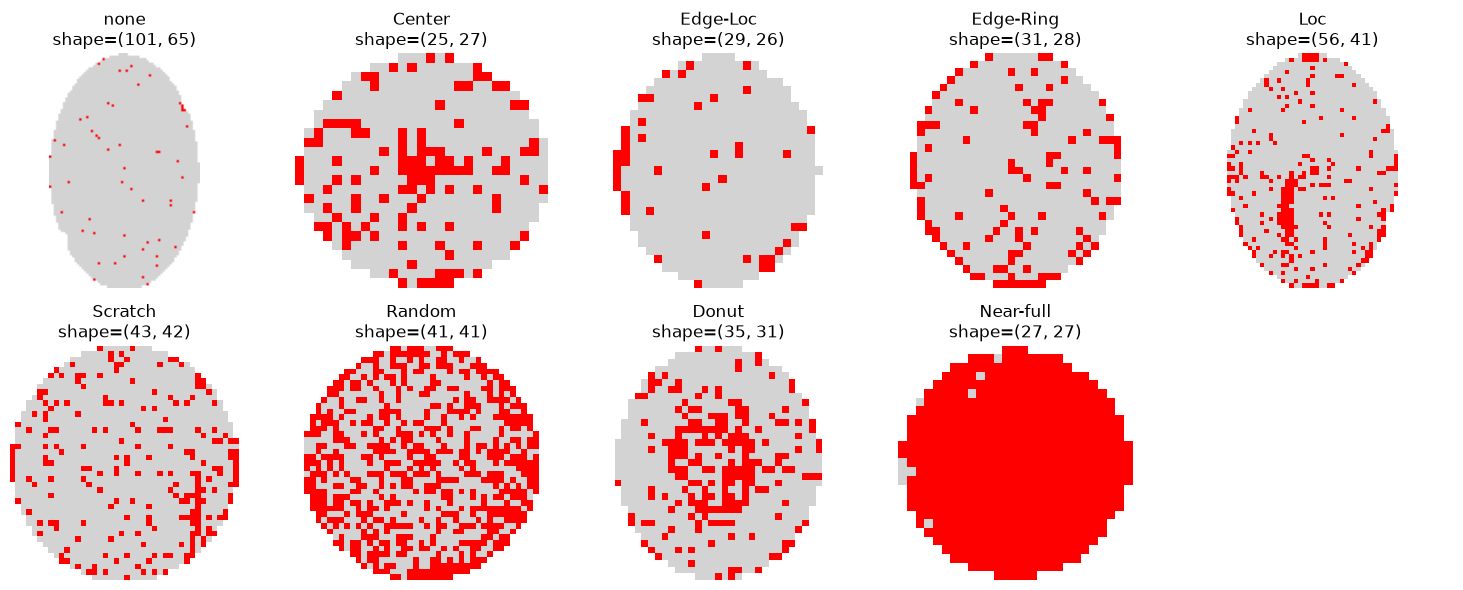

In [13]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

# Custom colors: 0=background(white), 1=pass(lightgray), 2=fail(red)
colors = ['white', 'lightgray', 'red']
cmap = ListedColormap(colors)

labels_to_show = train_df['label'].unique()
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for i, lbl in enumerate(labels_to_show):
    # Grab one example wafer map for this label
    sample = train_df[train_df['label'] == lbl].iloc[0]['waferMap']
    sample = np.array(sample)
    axes[i].imshow(sample, cmap=cmap, vmin=0, vmax=2)
    axes[i].set_title(f"{lbl}\nshape={sample.shape}")
    axes[i].axis('off')

# Hide unused subplot if fewer than 10 classes
for j in range(len(labels_to_show), len(axes)):
   axes[j].axis('off')

plt.tight_layout()
plt.show()

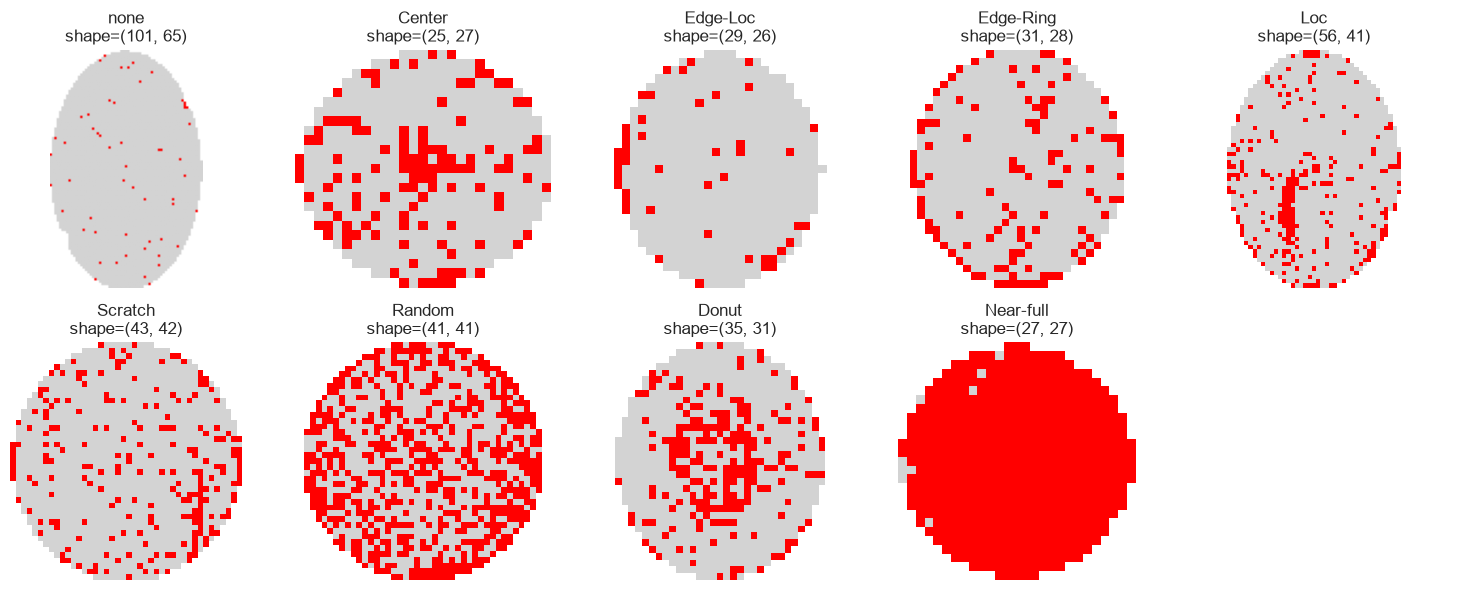

In [14]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import ListedColormap

plt.style.use('seaborn-v0_8-whitegrid')


# Custom colors: 0=background(white), 1=pass(lightgray), 2=fail(red)
colors = ['white', 'lightgray', 'red']
cmap = ListedColormap(colors)

labels_to_show = train_df['label'].unique()
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.flatten()

for i, lbl in enumerate(labels_to_show):
    # Grab one example wafer map for this label
    sample = train_df[train_df['label'] == lbl].iloc[0]['waferMap']
    sample = np.array(sample)
    axes[i].imshow(sample, cmap=cmap, vmin=0, vmax=2)
    axes[i].set_title(f"{lbl}\nshape={sample.shape}")
    axes[i].axis('off')

# Hide unused subplot if fewer than 10 classes
for j in range(len(labels_to_show), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

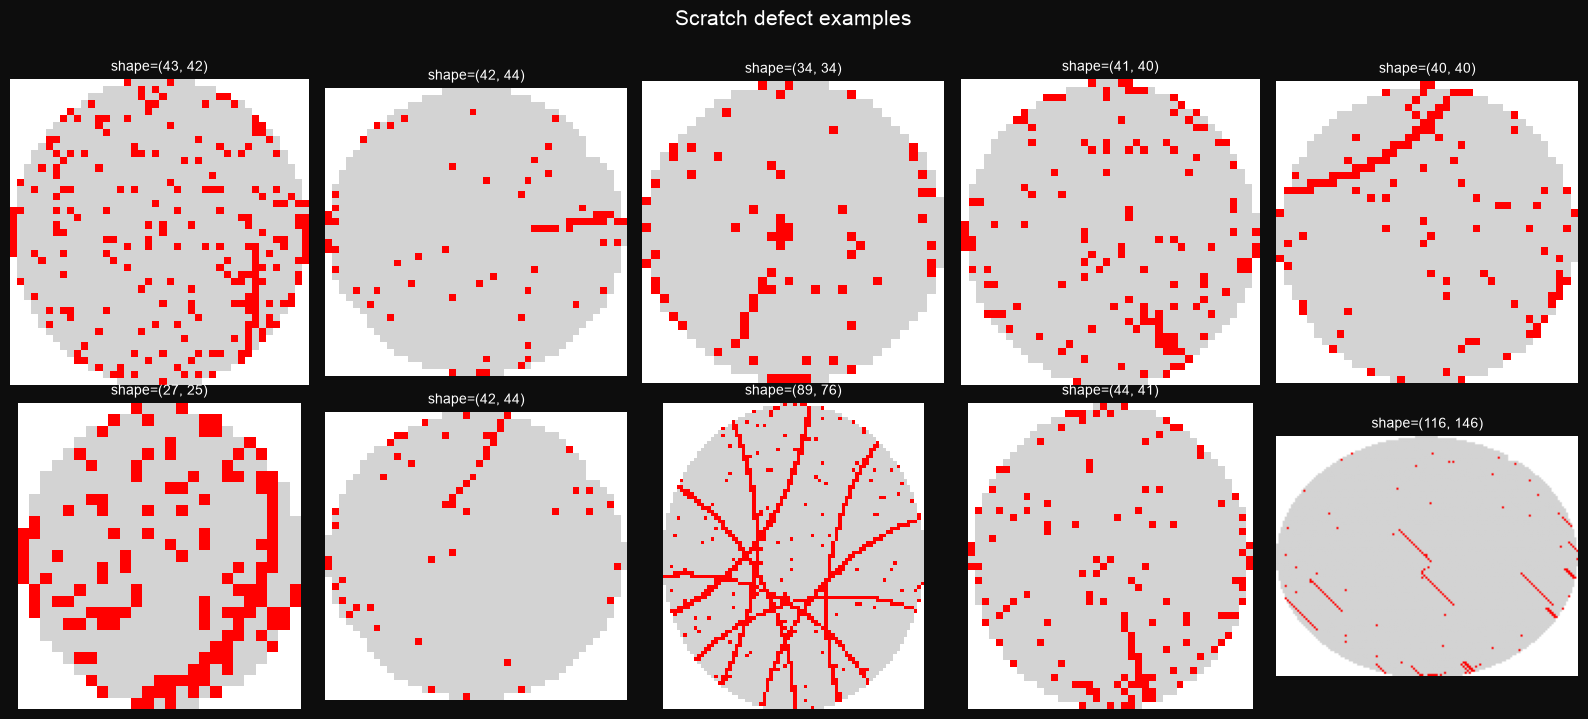

In [15]:
scratch_samples = train_df[train_df['label'] == 'Scratch'].head(10)
fig, axes = plt.subplots(2, 5, figsize=(16, 7), facecolor='#0d0d0d')
axes = axes.flatten()

for i, (_, row) in enumerate(scratch_samples.iterrows()):
    sample = np.array(row['waferMap'])
    axes[i].imshow(sample, cmap=cmap, vmin=0, vmax=2)
    axes[i].set_title(f"shape={sample.shape}", fontsize=10, color='white')
    axes[i].axis('off')

fig.suptitle('Scratch defect examples', fontsize=15, color='white', y=1.02)
plt.tight_layout()
plt.show()

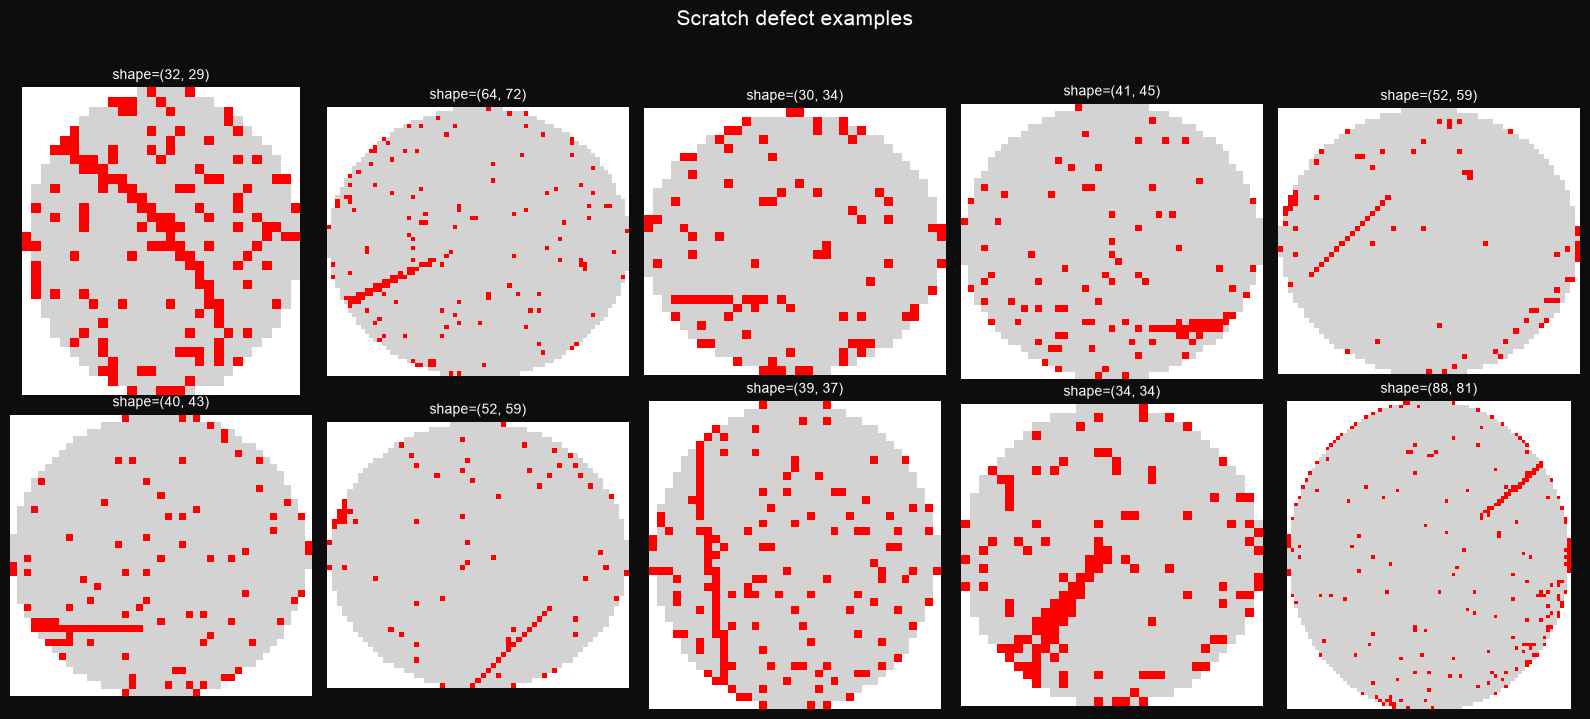

In [16]:
scratch_samples = train_df[train_df['label'] == 'Scratch'].sample(10, random_state=42)
fig, axes = plt.subplots(2, 5, figsize=(16, 7), facecolor='#0d0d0d')
axes = axes.flatten()

for i, (_, row) in enumerate(scratch_samples.iterrows()):
    sample = np.array(row['waferMap'])
    axes[i].imshow(sample, cmap=cmap, vmin=0, vmax=2)
    axes[i].set_title(f"shape={sample.shape}", fontsize=10, color='white')
    axes[i].axis('off')

fig.suptitle('Scratch defect examples', fontsize=15, color='white', y=1.02)
plt.tight_layout()
plt.show()

In [17]:
#defect density extraction

import numpy as np
import pandas as pd

def extract_density_features(wafer_map, n_regions=3):
    """
    Splits the wafer into an n_regions x n_regions grid and computes
    the fraction of failed dies (value=2) among existing dies (value!=0)
    in each region.
    """
    wafer_map = np.array(wafer_map)
    rows, cols = wafer_map.shape
    
    row_bins = np.array_split(np.arange(rows), n_regions)
    col_bins = np.array_split(np.arange(cols), n_regions)
    
    features = []
    for r_idx in row_bins:
        for c_idx in col_bins:
            region = wafer_map[np.ix_(r_idx, c_idx)]
            valid_dies = region[region != 0]
            if len(valid_dies) == 0:
                density = 0.0
            else:
                density = np.sum(valid_dies == 2) / len(valid_dies)
            features.append(density)
    
    return features

# Apply to the full training set
density_feature_names = [f'density_r{i}' for i in range(9)]
density_features = train_df['waferMap'].apply(lambda x: extract_density_features(x, n_regions=3))
density_df = pd.DataFrame(density_features.tolist(), columns=density_feature_names)
density_df['label'] = train_df['label'].values

# Sanity check: average density per region, grouped by class
print(density_df.groupby('label').mean().round(3))

           density_r0  density_r1  density_r2  density_r3  density_r4  \
label                                                                   
Center          0.190       0.197       0.200       0.194       0.465   
Donut           0.182       0.299       0.174       0.321       0.376   
Edge-Loc        0.199       0.180       0.210       0.177       0.124   
Edge-Ring       0.218       0.127       0.221       0.131       0.067   
Loc             0.137       0.148       0.140       0.141       0.171   
Near-full       0.893       0.881       0.840       0.903       0.913   
Random          0.480       0.474       0.462       0.470       0.500   
Scratch         0.103       0.096       0.106       0.092       0.089   
none            0.112       0.102       0.112       0.098       0.093   

           density_r5  density_r6  density_r7  density_r8  
label                                                      
Center          0.198       0.186       0.189       0.210  
Donut           

In [18]:
density_df.shape

(138360, 10)

In [19]:
density_df.head()

,density_r0,density_r1,density_r2,density_r3,density_r4,density_r5,density_r6,density_r7,density_r8,label
0,0.010050,0.011158,0.016713,0.009695,0.008021,0.008811,0.015228,0.009749,0.013405,none
1,0.076923,0.050000,0.059829,0.033816,0.047619,0.031088,0.093220,0.062802,0.066667,none
2,0.106383,0.094118,0.055556,0.047059,0.022222,0.014085,0.025641,0.025641,0.032258,none
3,0.160000,0.068376,0.078125,0.173228,0.250000,0.095652,0.092308,0.149533,0.127273,none
4,0.075949,0.062016,0.057971,0.057554,0.083333,0.109375,0.075949,0.062016,0.101449,none


In [20]:
# geometric based features
import skimage
print(skimage.__version__)

0.26.0


In [21]:
import sys
!{sys.executable} -m pip install scikit-image

In [22]:
import skimage
print(skimage.__version__)


0.26.0


In [23]:
#geometric features
import numpy as np
import pandas as pd
from skimage.measure import label, regionprops

def extract_geometry_features(wafer_map):
    """
    Treats failed dies (value=2) as a binary blob, finds the largest
    connected component, and measures its shape.
    """

    wafer_map = np.array(wafer_map)
    binary_defect = (wafer_map==2).astype(int)

    total_dies = np.sum(wafer_map !=0)
    failed_dies = np.sum(binary_defect)
    area_ratio = failed_dies / total_dies if total_dies>0 else 0.0

    #lable connected grouos of gailed dies (a "blob" = adjacent failed dies)
    labeled_image = label(binary_defect)
    regions = regionprops(labeled_image)

    #No failures at all (e.g- none wafer_ -> no shape to measure
    if len(regions) ==0:
        return [area_ratio, 0.0, 0.0, 0.0, 0.0]

    #if there are multiple seperate defect blobs, focus on the biggest one
    larget = max(regions, key=lambda r: r.area)

    minor = largest.minir_axis_length
    major = largest.major_axis_length
    aspect_ratio = major/minor if minor>0 else major

    solidity = largest.solidity
    eccentricity = largest.eccentricity
    extent = largest.extent

    return[area_ratio, aspect_ratio, solidity, eccentricity, extent]

    #applying to full training set
    geometry_feature_names = ['area_ratio', 'aspect_ratio', 'solidity', 'eccentricity', 'extent']
    geometry_geatures = train_df['waferMap'].apply(extract_geometry_features)
    geometry_df = pd.DataFrame(geometry_features.tolist(), columsn=geometry_feature_names)
    geometry_df['label'] = train_df['label'].values

    #sanity check
    print(geometry_df.groupby('label').mean().round(3))

    
    

In [24]:
import numpy as np
import pandas as pd
from skimage.measure import label, regionprops

def extract_geometry_features(wafer_map):
    """
    Treats failed dies (value=2) as a binary blob, finds the largest
    connected component, and measures its shape.
    """
    wafer_map = np.array(wafer_map)
    binary_defect = (wafer_map == 2).astype(int)
    
    total_dies = np.sum(wafer_map != 0)
    failed_dies = np.sum(binary_defect)
    area_ratio = failed_dies / total_dies if total_dies > 0 else 0.0
    
    # Label connected groups of failed dies (a "blob" = adjacent failed dies)
    labeled_image = label(binary_defect)
    regions = regionprops(labeled_image)
    
    # No failures at all (e.g. a 'none' wafer) -> no shape to measure
    if len(regions) == 0:
        return [area_ratio, 0.0, 0.0, 0.0, 0.0]
    
    # If there are multiple separate defect blobs, focus on the biggest one
    largest = max(regions, key=lambda r: r.area)
    
    minor = largest.minor_axis_length
    major = largest.major_axis_length
    aspect_ratio = major / minor if minor > 0 else major
    
    solidity = largest.solidity
    eccentricity = largest.eccentricity
    extent = largest.extent
    
    return [area_ratio, aspect_ratio, solidity, eccentricity, extent]

# Apply to full training set
geometry_feature_names = ['area_ratio', 'aspect_ratio', 'solidity', 'eccentricity', 'extent']
geometry_features = train_df['waferMap'].apply(extract_geometry_features)
geometry_df = pd.DataFrame(geometry_features.tolist(), columns=geometry_feature_names)
geometry_df['label'] = train_df['label'].values

# Sanity check
print(geometry_df.groupby('label').mean().round(3))

/var/folders/9r/jdd70tq907s_ms_l_0vv4kjh0000gn/T/ipykernel_29243/312796549.py:28: FutureWarning: `RegionProperties.minor_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_minor_length` instead. 
  minor = largest.minor_axis_length
/var/folders/9r/jdd70tq907s_ms_l_0vv4kjh0000gn/T/ipykernel_29243/312796549.py:29: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  major = largest.major_axis_length
/var/folders/9r/jdd70tq907s_ms_l_0vv4kjh0000gn/T/ipykernel_29243/312796549.py:28: FutureWarning: `RegionProperties.minor_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_minor_length` instead. 
  minor = largest.minor_axis_length
/var/folders/9r/jdd70tq907s_ms_l_0vv4kjh0000gn/T/ipykernel_29243/312796549.py:29: FutureWarning: `RegionProperti

           area_ratio  aspect_ratio  solidity  eccentricity  extent
label                                                              
Center          0.233         1.509     0.634         0.665   0.454
Donut           0.274         1.592     0.519         0.705   0.377
Edge-Loc        0.183         3.175     0.602         0.891   0.385
Edge-Ring       0.151         1.644     0.135         0.470   0.093
Loc             0.150         1.985     0.649         0.784   0.458
Near-full       0.881         1.106     0.865         0.396   0.686
Random          0.481         1.386     0.490         0.562   0.372
Scratch         0.099         7.465     0.545         0.967   0.272
none            0.106         2.967     0.709         0.882   0.491


In [25]:
#corrcting the false cases arising from 'none' label. Now we are taking wafers with pixcels >5

def extract_geometry_features(wafer_map, min_blob_size=5):
    wafer_map = np.array(wafer_map)
    binary_defect = (wafer_map == 2).astype(int)
    
    total_dies = np.sum(wafer_map != 0)
    failed_dies = np.sum(binary_defect)
    area_ratio = failed_dies / total_dies if total_dies > 0 else 0.0
    
    labeled_image = label(binary_defect)
    regions = regionprops(labeled_image)
    
    if len(regions) == 0:
        return [area_ratio, 0.0, 0.0, 0.0, 0.0]
    
    largest = max(regions, key=lambda r: r.area)
    
    # Guard against unstable shape stats on tiny/noisy blobs
    if largest.area < min_blob_size:
        return [area_ratio, 1.0, 1.0, 0.0, 1.0]  # neutral values: "no real shape"
    
    minor = largest.minor_axis_length
    major = largest.major_axis_length
    aspect_ratio = major / minor if minor > 0 else major
    
    solidity = largest.solidity
    eccentricity = largest.eccentricity
    extent = largest.extent
    
    return [area_ratio, aspect_ratio, solidity, eccentricity, extent]

geometry_features = train_df['waferMap'].apply(extract_geometry_features)
geometry_df = pd.DataFrame(geometry_features.tolist(), columns=geometry_feature_names)
geometry_df['label'] = train_df['label'].values

print(geometry_df.groupby('label').mean().round(3))

/var/folders/9r/jdd70tq907s_ms_l_0vv4kjh0000gn/T/ipykernel_29243/2196937629.py:23: FutureWarning: `RegionProperties.minor_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_minor_length` instead. 
  minor = largest.minor_axis_length
/var/folders/9r/jdd70tq907s_ms_l_0vv4kjh0000gn/T/ipykernel_29243/2196937629.py:24: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  major = largest.major_axis_length


           area_ratio  aspect_ratio  solidity  eccentricity  extent
label                                                              
Center          0.233         1.506     0.634         0.664   0.455
Donut           0.274         1.592     0.519         0.705   0.377
Edge-Loc        0.183         3.175     0.602         0.891   0.385
Edge-Ring       0.151         1.644     0.135         0.470   0.093
Loc             0.150         1.984     0.649         0.784   0.458
Near-full       0.881         1.106     0.865         0.396   0.686
Random          0.481         1.386     0.490         0.562   0.372
Scratch         0.099         7.465     0.545         0.967   0.272
none            0.106         2.389     0.748         0.623   0.598


In [26]:
#Radon based features, observing at different angles

import numpy as np
import pandas as pd
from skimage.transform import radon

def extract_radon_features(wafer_map, n_angles=45):
    wafer_map = np.array(wafer_map)
    binary_defect = (wafer_map==2).astype(float)

    #skipping radon transform on wafers with no failures - nothing to project
    if binary_defect.sum()==0:
        return [0.0, 0.0, 0.0]

    angles = np.linspace(0, 180, n_angles, endpoint=False)
    #circle=False handles non-square wafer maps correctly (avoids skimage warnings)
    sinogram = radon(binary_defect, theta=angles, circle=False)

    #sum along each angles projection, then look at how that sum varies with angle
    projection_sums = sinogram.sum(axis=0)

    radon_max = projection_sums.max()
    radon_std = projection_sums.std()
    radon_mean = projection_sums.mean()

    return [radon_max, radon_std, radon_mean]

#applying to full training set
radon_feature_names = ['radon_max', 'radon_std', 'radon_mean']
radon_features = train_df['waferMap'].apply(extract_radon_features)
radon_df= pd.DataFrame(radon_features.tolist(), columns=radon_feature_names)
radon_df['label'] = train_df['label'].values

print(radon_df.groupby('label').mean().round(2))


           radon_max  radon_std  radon_mean
label                                      
Center        171.87       0.54      170.30
Donut         396.08       0.65      394.21
Edge-Loc      188.92       0.56      187.29
Edge-Ring     306.04       0.75      303.96
Loc           149.98       0.50      148.52
Near-full     747.67       0.48      746.33
Random        552.02       0.86      549.55
Scratch       131.25       0.52      129.72
none           84.02       0.46       82.68


In [27]:
import numpy as np
import pandas as pd
from skimage.transform import radon

def extract_radon_features(wafer_map, n_angles=45):
    wafer_map = np.array(wafer_map)
    binary_defect = (wafer_map == 2).astype(float)
    
    if binary_defect.sum() == 0:
        return [0.0, 0.0, 0.0]
    
    angles = np.linspace(0, 180, n_angles, endpoint=False)
    sinogram = radon(binary_defect, theta=angles, circle=False)
    projection_sums = sinogram.sum(axis=0)
    
    # Normalize into a distribution over angles (sums to 1) -
    # removes the "total defect amount" confound, leaves only "shape"
    total = projection_sums.sum()
    normalized = projection_sums / total if total > 0 else projection_sums
    
    radon_peak_fraction = normalized.max()
    radon_entropy = -np.sum(normalized * np.log(normalized + 1e-10))  # +1e-10 avoids log(0)
    radon_mean = projection_sums.mean()  # keep this - still a useful "total defect" signal
    
    return [radon_peak_fraction, radon_entropy, radon_mean]

radon_feature_names = ['radon_peak_fraction', 'radon_entropy', 'radon_mean']
radon_features = train_df['waferMap'].apply(extract_radon_features)
radon_df = pd.DataFrame(radon_features.tolist(), columns=radon_feature_names)
radon_df['label'] = train_df['label'].values

print(radon_df.groupby('label').mean().round(4))

           radon_peak_fraction  radon_entropy  radon_mean
label                                                    
Center                  0.0225         3.8067    170.3007
Donut                   0.0224         3.8067    394.2087
Edge-Loc                0.0225         3.8067    187.2921
Edge-Ring               0.0224         3.8067    303.9589
Loc                     0.0225         3.8067    148.5165
Near-full               0.0223         3.8067    746.3267
Random                  0.0223         3.8067    549.5478
Scratch                 0.0225         3.8066    129.7210
none                    0.0226         3.8066     82.6844


In [28]:
# implementing the randon feature according to the research paper

import numpy as np
import pandas as pd
from skimage.transform import radon
from scipy.interpolate import interp1d

def resample_1d(arr, target_len=10):
    """Resamples a 1D array to a fixed length using cubic interpolation,
    exactly as the paper does to Gmu and Gsigma."""
    arr = np.asarray(arr)
    if len(arr)<2:
        return np.full(target_len, arr[0] if len(arr) else 0.0)
    x_old = np.linspace(0, 1, len(arr))
    x_new = np.linspace(0, 1, target_len)
    # cubic interpolation needs at least 4 points; fall back to linear otherwise
    kind = 'cubic' if len(arr)>=4 else 'linear'
    f = interp1d(x_old, arr, kind=kind)
    return f(x_new)

def extract_radon_features(wafer_map, n_angles=45, target_len=10):
    wafer_map = np.array(wafer_map)
    binary_defect = (wafer_map==2).astype(float)

    if binary_defect.sum() ==0:
        # No defects at all -> flat zero profile for both mu and sigma
        return list(np.zeros(target_len))+list(np.zeros(target_len))

    angles = np.linspace(0, 180, n_angles, endpoint=False)
    G = radon(binary_defect, theta=angles, circle=False)  # shape: (rho, theta)

    ## Min-max normalize the WHOLE matrix, as in the paper
    g_min, g_max = G.min(), G.max()
    G_norm = (G - g_min)/(g_max - g_min) if g_max>g_min else np.zeros_like(G)

    # Collapse across theta (angle) for each rho (radial position)
    G_mu = G_norm.mean(axis=1)  #avg response at each radius, overall angles
    G_sigma = G_norm.std(axis=1) #how much that response varies by angle at each radius

    #resample both to the fixed lenght so that every wafer produces the same feature count
    R_mu = resample_1d(G_mu, target_len)
    R_sigma = resample_1d(G_sigma, target_len)

    return list(R_mu) + list(R_sigma)

#Apply to full training set
radon_feature_names = [f'radon_mu_{i}' for i in range(10)] + [f'radon_sigma_{i}' for i in range(10)]
radon_features = train_df['waferMap'].apply(extract_radon_features)
radon_df = pd.DataFrame(radon_features.tolist(), columns=radon_feature_names)
radon_df['label'] = train_df['label'].values

print(radon_df.shape)

                                                                    
    

(138360, 21)


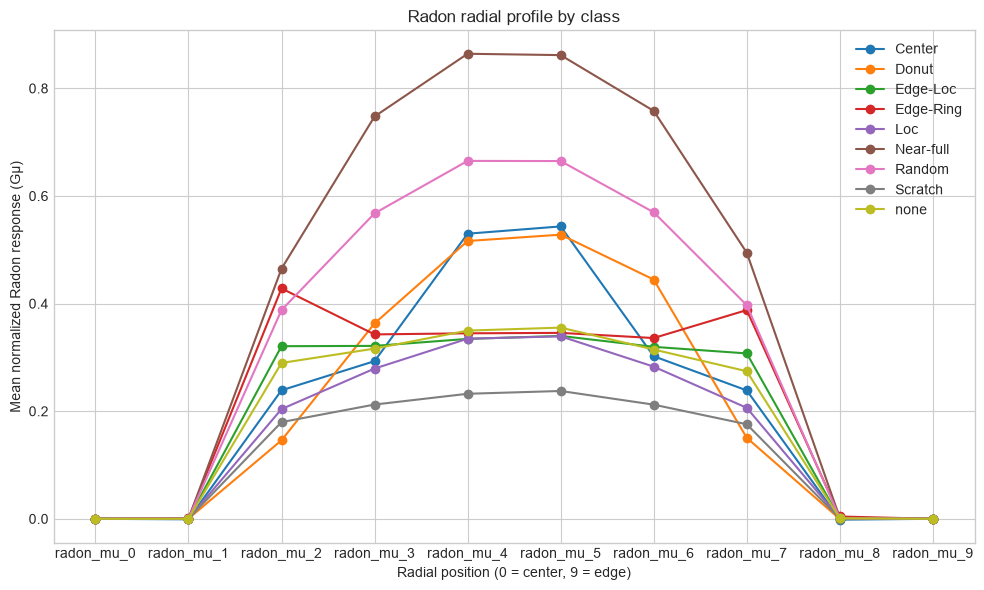

In [29]:
import matplotlib.pyplot as plt

mu_cols = [f'radon_mu_{i}' for i in range(10)]
class_profiles = radon_df.groupby('label')[mu_cols].mean()

plt.figure(figsize=(10, 6))
for lbl in class_profiles.index:
    plt.plot(class_profiles.loc[lbl], marker='o', label=lbl)
plt.xlabel('Radial position (0 = center, 9 = edge)')
plt.ylabel('Mean normalized Radon response (Gμ)')
plt.title('Radon radial profile by class')
plt.legend()
plt.tight_layout()
plt.show()

In [30]:
#now combining all the steps - desity, geometry and radon features together

X_train = pd.concat([
    density_df.drop(columns=['label']),
    geometry_df.drop(columns=['label']),
    radon_df.drop(columns=['label'])
], axis=1)

Y_train = train_df['label'].values  #use train_df directly - the authoritative

print(X_train.shape)
print(X_train.columns.tolist())

(138360, 34)
['density_r0', 'density_r1', 'density_r2', 'density_r3', 'density_r4', 'density_r5', 'density_r6', 'density_r7', 'density_r8', 'area_ratio', 'aspect_ratio', 'solidity', 'eccentricity', 'extent', 'radon_mu_0', 'radon_mu_1', 'radon_mu_2', 'radon_mu_3', 'radon_mu_4', 'radon_mu_5', 'radon_mu_6', 'radon_mu_7', 'radon_mu_8', 'radon_mu_9', 'radon_sigma_0', 'radon_sigma_1', 'radon_sigma_2', 'radon_sigma_3', 'radon_sigma_4', 'radon_sigma_5', 'radon_sigma_6', 'radon_sigma_7', 'radon_sigma_8', 'radon_sigma_9']


In [31]:
# building the test dataset
def extract_all_features(wafer_map):
    density = extract_density_features(wafer_map, n_regions=3)
    geometry = extract_geometry_features(wafer_map, min_blob_size=5)
    radon = extract_radon_features(wafer_map, n_angles=45, target_len=10)
    return density + geometry + radon

all_feature_names = density_feature_names + ['area_ratio', 'aspect_ratio', 'solidity', 'eccentricity', 'extent'] + radon_feature_names

# Apply once to the test set
test_features = test_df['waferMap'].apply(extract_all_features)
X_test = pd.DataFrame(test_features.tolist(), columns=all_feature_names)
y_test = test_df['label'].values

print(X_test.shape)

/var/folders/9r/jdd70tq907s_ms_l_0vv4kjh0000gn/T/ipykernel_29243/2196937629.py:23: FutureWarning: `RegionProperties.minor_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_minor_length` instead. 
  minor = largest.minor_axis_length
/var/folders/9r/jdd70tq907s_ms_l_0vv4kjh0000gn/T/ipykernel_29243/2196937629.py:24: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  major = largest.major_axis_length


(34590, 34)


In [32]:
#SVM is sensitive to a feature scale, so need to normalise all data into a standart 
#zero mean, unit variance normal curve

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

# Fit ONLY on training data - this is important
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)  # transform, not fit_transform

In [33]:
#Now doing the SVM classifier 

from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report
import time

print("Training the beast LinearSCV...")
start = time.time()
svm_model = LinearSVC(class_weight='balanced', max_iter=5000, random_state=42)
svm_model.fit(X_train_scaled, Y_train)
print(f"SVM training time: {time.time() - start:.1f}s")

svm_preds = svm_model.predict(X_test_scaled)
print("\n--- SVM Results ---")
print(classification_report(y_test, svm_preds))   #y is small as defined up

Training the beast LinearSCV...
SVM training time: 2.7s

--- SVM Results ---
              precision    recall  f1-score   support

      Center       0.71      0.83      0.77       859
       Donut       0.33      0.72      0.45       111
    Edge-Loc       0.59      0.55      0.57      1038
   Edge-Ring       0.96      0.96      0.96      1936
         Loc       0.34      0.36      0.35       718
   Near-full       1.00      0.63      0.78        30
      Random       0.49      0.82      0.62       173
     Scratch       0.28      0.80      0.42       239
        none       0.98      0.95      0.96     29486

    accuracy                           0.92     34590
   macro avg       0.63      0.74      0.65     34590
weighted avg       0.94      0.92      0.93     34590



In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

labels_order = sorted(y_test.tolist() if hasattr(y_test, 'tolist') else list(set(y_test)))
cm = confusion_matrix(y_test, svm_preds, labels=labels_order)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels_order, yticklabels=labels_order)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('SVM Confusion Matrix')
plt.tight_layout()
plt.show()